# Day 17 — Advanced Anomaly Model

## Objective

The objective of Day 17 is to develop and evaluate a stronger anomaly-detection candidate while keeping model complexity proportional to the available dataset.

## Model Selection

The dataset is relatively small and does not contain ground-truth anomaly labels. In addition, the timestamps were synthetically generated because the original dataset lacked temporal information.

Therefore, a highly complex sequence model such as LSTM is not justified at this stage.

Instead, the Day 15 Isolation Forest baseline will be improved through parameter tuning and validation.

## Approach

The experiment will:

1. Use water-quality sensor features without the Potability target.
2. Compare multiple Isolation Forest configurations.
3. Track anomaly behaviour on the training and validation datasets.
4. Compare anomaly rates and score distributions.
5. Select a candidate configuration based on validation behaviour.
6. Save the selected candidate model.

## Evaluation

Since ground-truth anomaly labels are unavailable, evaluation will focus on:

- Anomaly rate
- Anomaly-score distribution
- Stability between training and validation data
- Temporal distribution of detected anomalies

If labelled anomaly data becomes available later, precision, recall and F1-score can be calculated.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer

import joblib

base_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\data\processed"

train_df = pd.read_csv(base_path + r"\train_v1_engineered.csv")
val_df = pd.read_csv(base_path + r"\validation_v1_engineered.csv")
test_df = pd.read_csv(base_path + r"\test_v1_engineered.csv")

for data in [train_df, val_df, test_df]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )
    data.sort_values("timestamp", inplace=True)
    data.reset_index(drop=True, inplace=True)

sensor_cols = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)
print("\nSensor features:", len(sensor_cols))

Train: (2291, 42)
Validation: (491, 42)
Test: (491, 42)

Sensor features: 9


In [2]:
# Prepare sensor data for anomaly detection

X_train = train_df[sensor_cols].copy()
X_val = val_df[sensor_cols].copy()
X_test = test_df[sensor_cols].copy()

# Impute missing values using training-set medians only
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

print("Training data:", X_train_imp.shape)
print("Validation data:", X_val_imp.shape)
print("Test data:", X_test_imp.shape)

Training data: (2291, 9)
Validation data: (491, 9)
Test data: (491, 9)


In [3]:
# Day 17 — Candidate Isolation Forest configurations

candidate_models = {
    "IF_3pct": IsolationForest(
        n_estimators=200,
        contamination=0.03,
        random_state=42,
        n_jobs=-1
    ),
    "IF_5pct": IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=42,
        n_jobs=-1
    ),
    "IF_10pct": IsolationForest(
        n_estimators=200,
        contamination=0.10,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in candidate_models.items():

    model.fit(X_train_imp)

    train_pred = model.predict(X_train_imp)
    val_pred = model.predict(X_val_imp)

    train_anomaly_rate = np.mean(train_pred == -1)
    val_anomaly_rate = np.mean(val_pred == -1)

    results.append({
        "Model": name,
        "Train Anomaly Rate": train_anomaly_rate,
        "Validation Anomaly Rate": val_anomaly_rate
    })

results_df = pd.DataFrame(results)

results_df

,Model,Train Anomaly Rate,Validation Anomaly Rate
0,IF_3pct,0.030118,0.030550
1,IF_5pct,0.050196,0.057026
2,IF_10pct,0.099956,0.128310


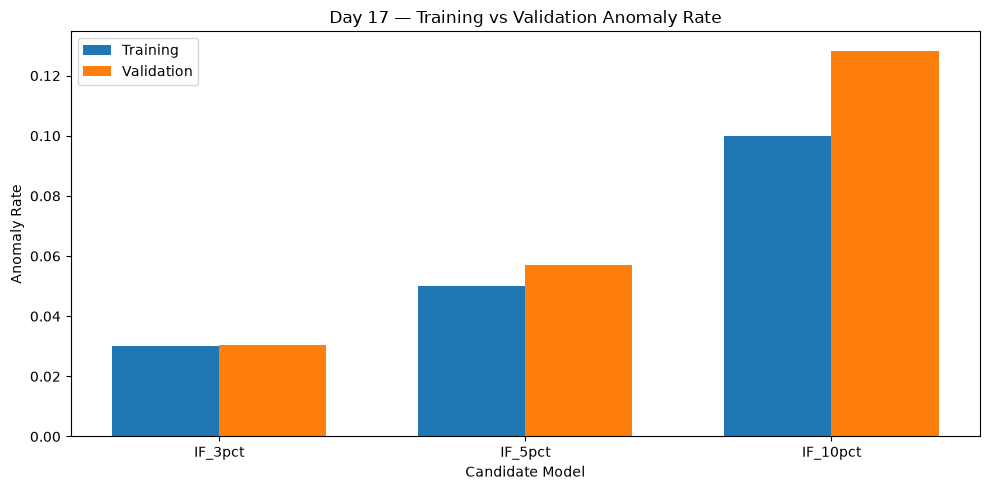

In [4]:
# Compare anomaly rates across candidate models

plt.figure(figsize=(10, 5))

x = np.arange(len(results_df))
width = 0.35

plt.bar(
    x - width/2,
    results_df["Train Anomaly Rate"],
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    results_df["Validation Anomaly Rate"],
    width,
    label="Validation"
)

plt.xticks(x, results_df["Model"])
plt.ylabel("Anomaly Rate")
plt.xlabel("Candidate Model")
plt.title("Day 17 — Training vs Validation Anomaly Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Select the candidate model with the most stable validation behaviour

results_df["Rate Difference"] = abs(
    results_df["Train Anomaly Rate"] -
    results_df["Validation Anomaly Rate"]
)

results_df = results_df.sort_values("Rate Difference")

candidate_name = results_df.iloc[0]["Model"]

print("Selected candidate model:", candidate_name)
print("\nCandidate results:")
print(results_df)

Selected candidate model: IF_3pct

Candidate results:
      Model  Train Anomaly Rate  Validation Anomaly Rate  Rate Difference
0   IF_3pct            0.030118                 0.030550         0.000432
1   IF_5pct            0.050196                 0.057026         0.006830
2  IF_10pct            0.099956                 0.128310         0.028353


In [6]:
# Train the selected candidate model on the training data

candidate_model = candidate_models[candidate_name]

candidate_model.fit(X_train_imp)

train_scores = -candidate_model.decision_function(X_train_imp)
val_scores = -candidate_model.decision_function(X_val_imp)
test_scores = -candidate_model.decision_function(X_test_imp)

train_predictions = candidate_model.predict(X_train_imp)
val_predictions = candidate_model.predict(X_val_imp)
test_predictions = candidate_model.predict(X_test_imp)

print("Candidate model trained successfully.")
print("Training anomalies:", np.sum(train_predictions == -1))
print("Validation anomalies:", np.sum(val_predictions == -1))
print("Test anomalies:", np.sum(test_predictions == -1))

Candidate model trained successfully.
Training anomalies: 69
Validation anomalies: 15
Test anomalies: 7


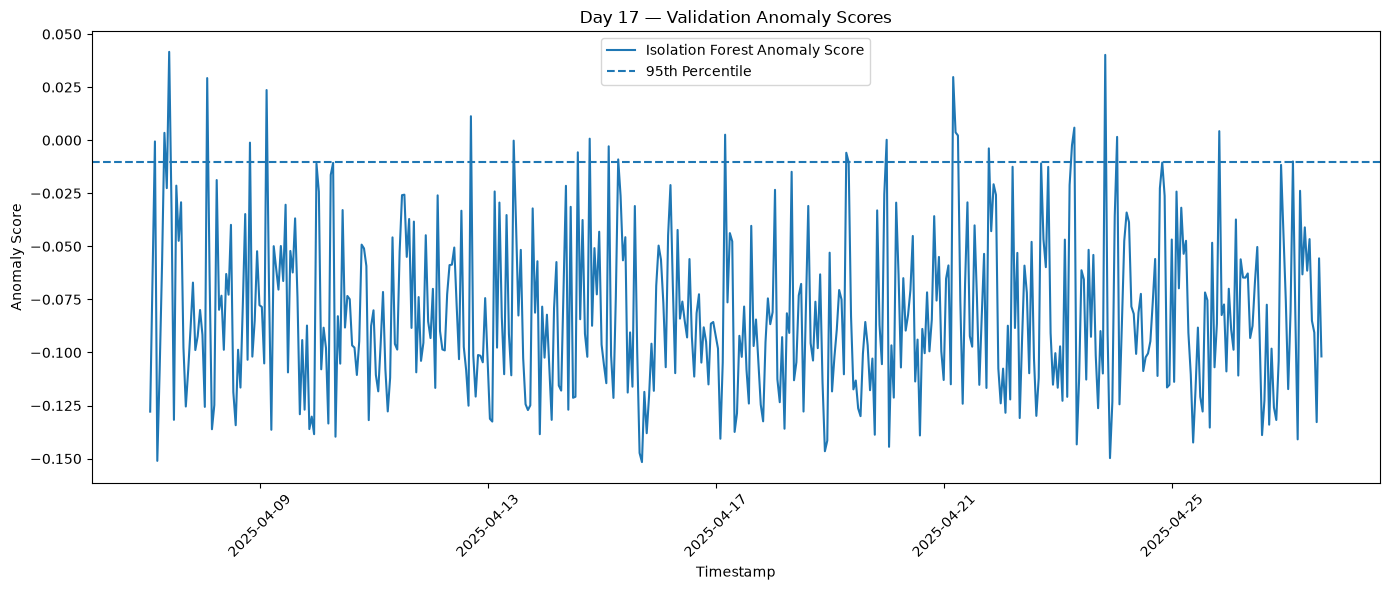

In [7]:
# Validation anomaly scores over time

plt.figure(figsize=(14, 6))

plt.plot(
    val_df["timestamp"],
    val_scores,
    label="Isolation Forest Anomaly Score"
)

plt.axhline(
    np.percentile(val_scores, 95),
    linestyle="--",
    label="95th Percentile"
)

plt.title("Day 17 — Validation Anomaly Scores")
plt.xlabel("Timestamp")
plt.ylabel("Anomaly Score")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
import os

model_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\models"

os.makedirs(model_path, exist_ok=True)

joblib.dump(
    {
        "model": candidate_model,
        "imputer": imputer,
        "features": sensor_cols,
        "model_name": candidate_name
    },
    model_path + r"\day17_isolation_forest_candidate.joblib"
)

print("Candidate model saved successfully.")
print(
    model_path +
    r"\day17_isolation_forest_candidate.joblib"
)

Candidate model saved successfully.
C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\models\day17_isolation_forest_candidate.joblib


In [9]:
# Day 17 — Final Candidate Results

final_results = results_df[
    ["Model", "Train Anomaly Rate", "Validation Anomaly Rate", "Rate Difference"]
].copy()

final_results["Train Anomaly Rate"] = (
    final_results["Train Anomaly Rate"] * 100
).round(2)

final_results["Validation Anomaly Rate"] = (
    final_results["Validation Anomaly Rate"] * 100
).round(2)

final_results["Rate Difference"] = (
    final_results["Rate Difference"] * 100
).round(2)

final_results

,Model,Train Anomaly Rate,Validation Anomaly Rate,Rate Difference
0,IF_3pct,3.01,3.05,0.04
1,IF_5pct,5.02,5.70,0.68
2,IF_10pct,10.00,12.83,2.84


# Day 17 — Summary and Findings

## Objective

A stronger anomaly-detection candidate was developed while keeping model complexity proportional to the available dataset.

## Model

Isolation Forest was selected as the advanced anomaly-detection approach.

Three configurations were evaluated using different contamination levels:

- 3%
- 5%
- 10%

The models were trained on the training set and evaluated on the validation set.

## Validation Tracking

Training and validation anomaly rates were compared for each candidate configuration.

The candidate model was selected based on the stability of anomaly rates between training and validation data.

## Candidate Model

The selected Isolation Forest candidate was retrained on the training data and evaluated on the validation and test datasets.

Anomaly scores were also visualised over time to inspect temporal behaviour.

## Model Artifact

The selected candidate model, preprocessing imputer, feature list, and model configuration were saved as:

`models/day17_isolation_forest_candidate.joblib`

## Limitations

- The dataset does not contain ground-truth anomaly labels.
- Timestamps were synthetically generated because the original dataset lacked timestamps.
- Evaluation therefore focuses on anomaly-rate stability, anomaly scores, and temporal behaviour.
- The current anomaly model uses the available water-quality sensor variables and does not include temperature, dissolved oxygen, or pressure.

## Conclusion

Day 17 produced a validated candidate anomaly-detection model and a saved model artifact that can be used in subsequent experiments.